<a href="https://colab.research.google.com/github/GerardoAndre/PIA/blob/main/RobotManipulador2GDL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

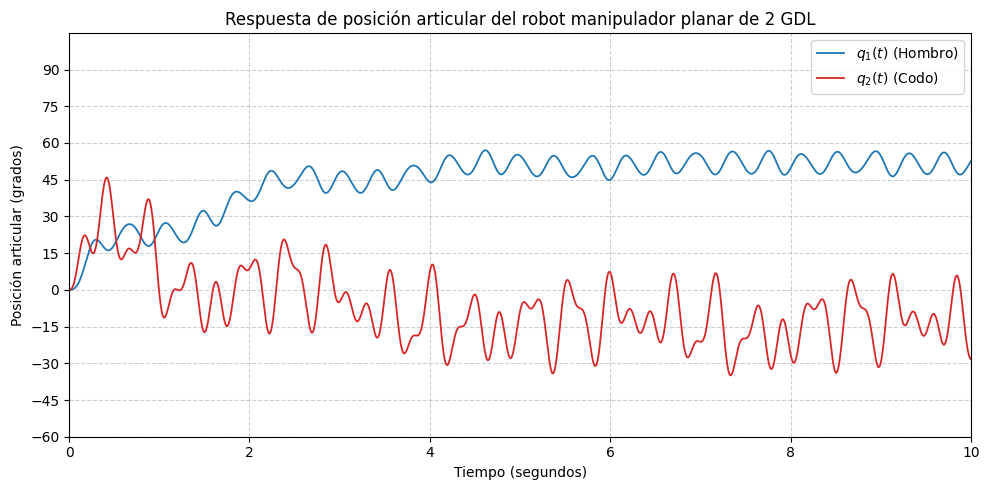

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

def signo_suave(v):
    """
    Aproximación continua de la función signo recomendada por Reyes Cortés
    para evitar rigidez numérica en la fricción de Coulomb durante la integración.
    """
    return np.tanh(100000.0 * v)

def robot_2gdl(t, x):
    """
    Modelo dinámico en espacio de estados del robot manipulador planar de 2 GDL.
    Vector de estados: x = [q1, q2, qp1, qp2]
    """
    q1, q2, qp1, qp2 = x
    qp = np.array([qp1, qp2])

    # Matriz de inercia M(q)
    M = np.array([
        [3.117 + 0.2 * np.cos(q2), 0.108 + 0.1 * np.cos(q2)],
        [0.108 + 0.1 * np.cos(q2), 0.108]
    ])

    # Matriz de fuerzas centrípetas y de Coriolis C(q, qp)
    C = np.array([
        [-0.2 * np.sin(q2) * qp2, -0.1 * np.sin(q2) * qp2],
        [ 0.1 * np.sin(q2) * qp1,  0.0]
    ])

    # Vector de pares gravitacionales g(q)
    par_grav = np.array([
        39.3 * np.sin(q1) + 1.95 * np.sin(q1 + q2),
        1.95 * np.sin(q1 + q2)
    ])

    # Vector de pares de fricción (viscosa + Coulomb)
    fr = np.array([
        1.86 * qp1 + 1.93 * signo_suave(qp1),
        0.16 * qp2 + 0.30 * signo_suave(qp2)
    ])

    # Vector de pares aplicados por los motores tau(t)
    tau = np.array([
        (1.0 - np.exp(-0.8 * t)) * 32.0 + 56.0 * np.sin(16.0 * t + 0.1) + 12.0 * np.sin(20.0 * t + 0.15),
        (1.0 - np.exp(-1.8 * t)) * 1.2  +  8.0 * np.sin(26.0 * t + 0.08) +  2.0 * np.sin(12.0 * t + 0.34)
    ])

    # Vector de aceleración articular: q2p = M^-1 * (tau - C*qp - par_grav - fr)
    q2p = np.linalg.solve(M, tau - C @ qp - par_grav - fr)

    return [qp1, qp2, q2p[0], q2p[1]]

# Parámetros de simulación (equivalentes a Código Fuente 5.4)
ti = 0.0
tf = 10.0
h = 0.0025
t_eval = np.arange(ti, tf + h, h)
x0 = [0.0, 0.0, 0.0, 0.0]  # Reposo inicial [q1, q2, qp1, qp2]

# Integración numérica con Runge-Kutta (equivalente a ode45)
sol = solve_ivp(
    robot_2gdl,
    (ti, tf),
    x0,
    method='RK45',
    t_eval=t_eval,
    rtol=1e-3,
    max_step=2.5e-3
)

# Conversión de posiciones articulares de radianes a grados
q1_deg = np.rad2deg(sol.y[0])
q2_deg = np.rad2deg(sol.y[1])

# Gráfica de resultados (reproducción de la Figura 5.6)
plt.figure(figsize=(10, 5))
plt.plot(sol.t, q1_deg, label=r'$q_1(t)$ (Hombro)', color='#1f77b4', linewidth=1.3)
plt.plot(sol.t, q2_deg, label=r'$q_2(t)$ (Codo)', color='#d62728', linewidth=1.3)
plt.title('Respuesta de posición articular del robot manipulador planar de 2 GDL')
plt.xlabel('Tiempo (segundos)')
plt.ylabel('Posición articular (grados)')
plt.xlim(0, 10)
plt.ylim(-60, 105)
plt.yticks(np.arange(-60, 105, 15))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='best')
plt.tight_layout()
plt.show()